Total registros combinados CABA/GBA: 18278
PERIODO  AGLOMERADO_TXT
T2 2016  CABA              2396
         GBA               8810
T2 2026  CABA              1427
         GBA               5645
dtype: int64

--- EVOLUCIÓN DE LA TASA DE NO RESPUESTA (%) ---


P21_CAT                 Declara Ingreso (>0)  Ingreso Cero (0)  \
PERIODO AGLOMERADO_TXT                                           
T2 2016 CABA                           71.94              2.98   
        GBA                            74.80              3.23   
T2 2026 CABA                           70.10              3.82   
        GBA                            64.00              2.27   

P21_CAT                 No Respuesta (-9)  
PERIODO AGLOMERADO_TXT                     
T2 2016 CABA                        25.08  
        GBA                         21.97  
T2 2026 CABA                        26.08  
        GBA                         33.73


--- RESUMEN DE DISTRIBUCIÓN Y OUTLIERS ---


Casos      Media    Mediana     Desvío        Q1  \
PERIODO AGLOMERADO_TXT                                                      
T2 2016 CABA            869.00   13426.43   10800.00   11731.17   7000.00   
        GBA            2710.00    9763.24    8000.00    8930.23   4800.00   
T2 2026 CABA            551.00 1697695.10 1300000.00 1635238.26 800000.00   
        GBA            1609.00 1067952.14  880000.00  957958.67 500000.00   

                               Q3        IQR  Límite Sup. Tukey  \
PERIODO AGLOMERADO_TXT                                            
T2 2016 CABA             16000.00    9000.00           29500.00   
        GBA              12000.00    7200.00           22800.00   
T2 2026 CABA           2000000.00 1200000.00         3800000.00   
        GBA            1300000.00  800000.00         2500000.00   

                        Cant. Outliers  % Outliers      Máximo  
PERIODO AGLOMERADO_TXT                                          
T2 2016 CABA                     62.00        7.13   100000.00  
        GBA                     139.00        5.13   150000.00  
T2 2026 CABA                     37.00        6.72 20000000.00  
        GBA                      77.00        4.79 11000000.00

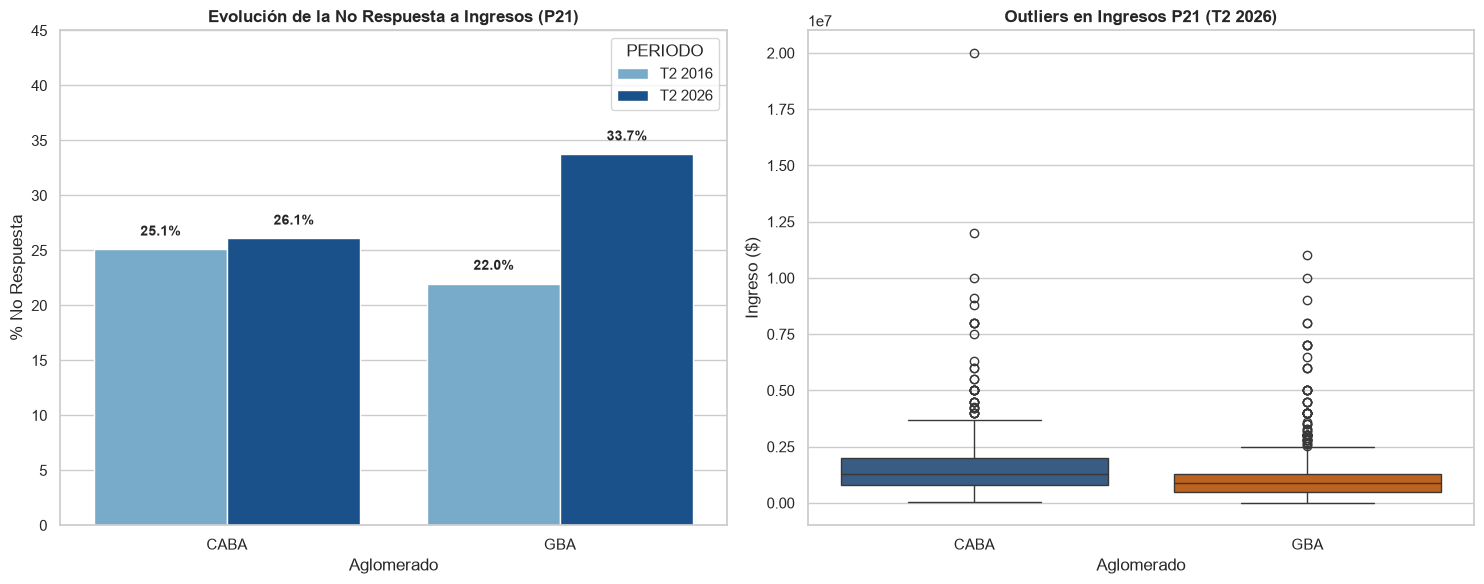

In [ ]:
# COMPARACIÓN HISTÓRICA DE PUNTAS (T2 2016 vs. T2 2026)

# Función para cargar y estandarizar cada trimestre
def cargar_trimestre_eph(ruta, periodo_nombre):
    df_temp = pd.read_csv(ruta, sep=";", low_memory=False)
    # Filtrar solo CABA (32) y GBA (33)
    df_temp = df_temp[df_temp['AGLOMERADO'].isin([32, 33])].copy()
    
    # Asegurar tipos numéricos en columnas críticas
    for col in ['P21', 'ESTADO', 'CH06', 'CH04', 'NIVEL_ED']:
        if col in df_temp.columns:
            df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')
            
    df_temp['PERIODO'] = periodo_nombre
    df_temp['AGLOMERADO_TXT'] = df_temp['AGLOMERADO'].map({32: 'CABA', 33: 'GBA'})
    return df_temp

# Cargar ambos archivos
df_2016 = cargar_trimestre_eph("../datos/raw/usu_individual_T216.txt", "T2 2016")
df_2026 = cargar_trimestre_eph("../datos/raw/usu_individual_T226.txt", "T2 2026")

# Unir ambos datasets para un análisis unificado
df_puntas = pd.concat([df_2016, df_2026], ignore_index=True)

print(f"Total registros combinados CABA/GBA: {len(df_puntas)}")
print(df_puntas.groupby(['PERIODO', 'AGLOMERADO_TXT']).size())


# EVOLUCIÓN DE LA NO RESPUESTA A INGRESOS
ocupados_puntas = df_puntas[df_puntas['ESTADO'] == 1].copy()

def clasificar_p21(val):
    if val == -9:
        return "No Respuesta (-9)"
    elif val == 0:
        return "Ingreso Cero (0)"
    elif val > 0:
        return "Declara Ingreso (>0)"
    else:
        return "Otro"

ocupados_puntas['P21_CAT'] = ocupados_puntas['P21'].apply(clasificar_p21)

# Tabla porcentual de respuesta por Período y Aglomerado
tabla_no_resp_comp = pd.crosstab(
    [ocupados_puntas['PERIODO'], ocupados_puntas['AGLOMERADO_TXT']],
    ocupados_puntas['P21_CAT'],
    normalize='index'
) * 100

print("\n--- EVOLUCIÓN DE LA TASA DE NO RESPUESTA (%) ---")
display(tabla_no_resp_comp.round(2))

# DETECCIÓN DE OUTLIERS Y MEDIDAS POR PERÍODO
ingresos_puntas = ocupados_puntas[ocupados_puntas['P21'] > 0].copy()

def resumen_outliers(df_sub):
    serie = df_sub['P21']
    q1 = serie.quantile(0.25)
    mediana = serie.median()
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    outliers = serie[serie > lim_sup]
    
    return pd.Series({
        'Casos': len(serie),
        'Media': serie.mean(),
        'Mediana': mediana,
        'Desvío': serie.std(),
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Límite Sup. Tukey': lim_sup,
        'Cant. Outliers': len(outliers),
        '% Outliers': (len(outliers) / len(serie)) * 100,
        'Máximo': serie.max()
    })

tabla_outliers = ingresos_puntas.groupby(['PERIODO', 'AGLOMERADO_TXT']).apply(resumen_outliers, include_groups=False)
print("\n--- RESUMEN DE DISTRIBUCIÓN Y OUTLIERS ---")
display(tabla_outliers.round(2))

# VISUALIZACIÓN COMPARATIVA
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Tasa de No Respuesta
tasa_nr_plot = tabla_no_resp_comp[['No Respuesta (-9)']].reset_index()
sns.barplot(
    data=tasa_nr_plot, 
    x='AGLOMERADO_TXT', 
    y='No Respuesta (-9)', 
    hue='PERIODO',
    palette=['#6baed6', '#08519c'],
    ax=axes[0]
)
axes[0].set_title('Evolución de la No Respuesta a Ingresos (P21)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('% No Respuesta')
axes[0].set_xlabel('Aglomerado')
axes[0].set_ylim(0, 45)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

# Gráfico 2: Boxplot 2026 (Para ver la dispersión y outliers actuales)
sns.boxplot(
    data=ingresos_puntas[ingresos_puntas['PERIODO'] == 'T2 2026'],
    x='AGLOMERADO_TXT',
    y='P21',
    hue='AGLOMERADO_TXT',
    legend=False,
    palette={'CABA': '#2b5c8f', 'GBA': '#d95f02'},
    ax=axes[1]
)
axes[1].set_title('Outliers en Ingresos P21 (T2 2026)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Ingreso ($)')
axes[1].set_xlabel('Aglomerado')

plt.tight_layout()
fig.savefig("punto1_comparacion_no_respuesta_y_outliers.png", dpi=300, bbox_inches='tight')
plt.show()